# Graph exploration

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

NODES_PATH = Path("..", "dataset", "node_features.csv")
EDGES_PATH = Path("..", "dataset", "edges.csv")

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Load and sanity-check the data

In [5]:
nodes = pd.read_csv(NODES_PATH)
edges = pd.read_csv(EDGES_PATH)

print(f"nodes: {nodes.shape}, edges: {edges.shape}")
display(nodes.head())
display(edges.head())

nodes: (7571, 16), edges: (21809, 3)


,acpl,accuracy,num_moves,frac_blunders,frac_mistakes,frac_inaccuracies,avg_move_time,last_theory_ply,target_rating,username,win_streak,loss_streak,num_games,win_rate,loss_rate,draw_rate
0,59.916667,78.500000,67.716667,0.032208,0.025386,0.056310,0.013222,4.800000,1805.0,simo_ecn,18,11,4591,0.485951,0.493357,0.020693
1,64.950000,76.783333,85.433333,0.036528,0.023679,0.048051,0.025250,3.550000,1653.0,Kazenkoekk,7,7,574,0.479094,0.459930,0.060976
2,66.083333,76.750000,60.416667,0.036955,0.018726,0.051871,0.009440,5.000000,1180.0,chentai2015,8,10,504,0.436508,0.523810,0.039683
3,64.500000,73.466667,61.433333,0.036701,0.021028,0.039526,0.013087,3.450000,1551.0,alopezpr,16,11,4156,0.490857,0.487247,0.021896
4,47.800000,82.033333,71.750000,0.026958,0.017767,0.043187,0.027324,5.466667,1789.0,Rathh_Nadnebesnie,11,6,518,0.554054,0.403475,0.042471


,from,to,points
0,anonimochess100,WaldAld,1.0
1,Yason1,anonimochess100,1.0
2,anonimochess100,shekharfromcal,1.0
3,WinandFail,anonimochess100,1.0
4,anonimochess100,Stelog,1.0


In [6]:
display(nodes.describe().T)
print("Missing values per node column:")
print(nodes.isna().sum()[lambda s: s > 0])

/home/ruben/Projects/GraphML-Lichess/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
acpl,7571.0,66.048211,17.459098,13.600000,54.366667,64.050000,74.783333,2.560000e+02
accuracy,7571.0,76.168879,5.293095,41.900000,73.149468,76.500000,79.650000,9.610000e+01
num_moves,7571.0,66.557490,8.687624,36.933333,60.500000,66.083333,72.200000,1.116833e+02
frac_blunders,7571.0,0.038233,0.011369,0.002340,0.030634,0.037235,0.044629,1.240533e-01
frac_mistakes,7571.0,0.022666,0.005467,0.001389,0.019061,0.022246,0.025900,5.345604e-02
frac_inaccuracies,7571.0,0.048729,0.008803,0.003639,0.042931,0.048170,0.053862,9.473249e-02
avg_move_time,7571.0,inf,NaN,0.004550,0.013097,0.016393,0.020987,inf
last_theory_ply,7571.0,4.648067,0.857041,1.071429,4.116667,4.727273,5.250000,7.058824e+00
target_rating,7571.0,1532.263373,308.126084,400.000000,1326.000000,1539.000000,1734.000000,2.591000e+03
win_streak,7571.0,9.900013,4.511768,1.000000,8.000000,9.000000,12.000000,1.050000e+02


Missing values per node column:
Series([], dtype: int64)


In [10]:
node_ids = set(nodes["username"])
edge_ids = set(edges["from"]) | set(edges["to"])

print("duplicate usernames in nodes:     ", nodes["username"].duplicated().sum())
print("duplicate (from, to) pairs:       ", edges.duplicated(["from", "to"]).sum())
print("self-loops:                       ", (edges["from"] == edges["to"]).sum())
print("edge endpoints missing from nodes:", len(edge_ids - node_ids))
print("nodes with no edges at all:       ", len(node_ids - edge_ids))

duplicate usernames in nodes:      0
duplicate (from, to) pairs:        6134
self-loops:                        0
edge endpoints missing from nodes: 0
nodes with no edges at all:        32


## 2. Build the graph

In [11]:
# Collapse duplicate (from, to) pairs by summing points
edges_agg = edges.groupby(["from", "to"], as_index=False)["points"].sum()

G = nx.DiGraph()
G.add_nodes_from(nodes.drop_duplicates("username").set_index("username").to_dict("index").items())
G.add_weighted_edges_from(edges_agg[["from", "to", "points"]].itertuples(index=False, name=None))

UG = nx.Graph(G)   # undirected view, used for clustering / communities
print(G)

DiGraph with 7571 nodes and 15675 edges


## 3. Global characteristics

In [12]:
n, m = G.number_of_nodes(), G.number_of_edges()
summary = {
    "nodes": n,
    "edges": m,
    "density": nx.density(G),
    "avg degree": 2 * UG.number_of_edges() / n,
    "isolated nodes": nx.number_of_isolates(G),
    "self-loops": nx.number_of_selfloops(G),
    "total points": edges_agg["points"].sum(),
}
summary["reciprocity"] = nx.reciprocity(G)
wcc = list(nx.weakly_connected_components(G))
scc = list(nx.strongly_connected_components(G))
summary["weak components"] = len(wcc)
summary["largest weak component"] = max(map(len, wcc))
summary["strong components"] = len(scc)
summary["largest strong component"] = max(map(len, scc))
summary["avg clustering (undirected)"] = nx.average_clustering(UG)
summary["transitivity"] = nx.transitivity(UG)
pd.Series(summary, name="value").to_frame()

,value
nodes,7571.000000
edges,15675.000000
density,0.000274
avg degree,3.656056
isolated nodes,32.000000
self-loops,0.000000
total points,27774.000000
reciprocity,0.234131
weak components,63.000000
largest weak component,7463.000000


In [13]:
# Distances on the largest connected component (undirected view).
# Exact diameter is expensive on big graphs, so only compute it for modest sizes.
lcc_nodes = max(nx.connected_components(UG), key=len)
LCC = UG.subgraph(lcc_nodes)
print(f"largest component: {LCC.number_of_nodes()} nodes")

if LCC.number_of_nodes() <= 10000:
    print("diameter:", nx.diameter(LCC))
    print("avg shortest path:", round(nx.average_shortest_path_length(LCC), 3))
else:
    rng = np.random.default_rng(0)
    sample = rng.choice(list(LCC.nodes), 200, replace=False)
    lengths = [l for s in sample for l in nx.single_source_shortest_path_length(LCC, s).values()]
    print("(sampled) avg shortest path:", round(np.mean(lengths), 3), " max seen:", max(lengths))

largest component: 7463 nodes
diameter: 26
avg shortest path: 7.515


## 4. Degree and strength distributions

In [14]:
metrics = pd.DataFrame(index=list(G.nodes))
metrics["in_degree"] = pd.Series(dict(G.in_degree()))
metrics["out_degree"] = pd.Series(dict(G.out_degree()))
metrics["in_points"] = pd.Series(dict(G.in_degree(weight="weight")))
metrics["out_points"] = pd.Series(dict(G.out_degree(weight="weight")))
metrics["degree"] = pd.Series(dict(UG.degree()))
metrics["strength"] = pd.Series(dict(UG.degree(weight="weight")))
metrics.describe().T

,count,mean,std,min,25%,50%,75%,max
in_degree,7571.0,2.070400,1.817553,0.0,1.0,2.0,3.0,24.0
out_degree,7571.0,2.070400,1.835993,0.0,1.0,2.0,3.0,25.0
in_points,7571.0,3.668472,5.696141,0.0,1.0,2.5,4.0,114.0
out_points,7571.0,3.668472,5.866518,0.0,1.0,2.5,4.0,150.0
degree,7571.0,3.656056,2.451548,0.0,2.0,3.0,4.0,38.0
strength,7571.0,6.102100,6.452085,0.0,3.0,5.0,7.0,158.0


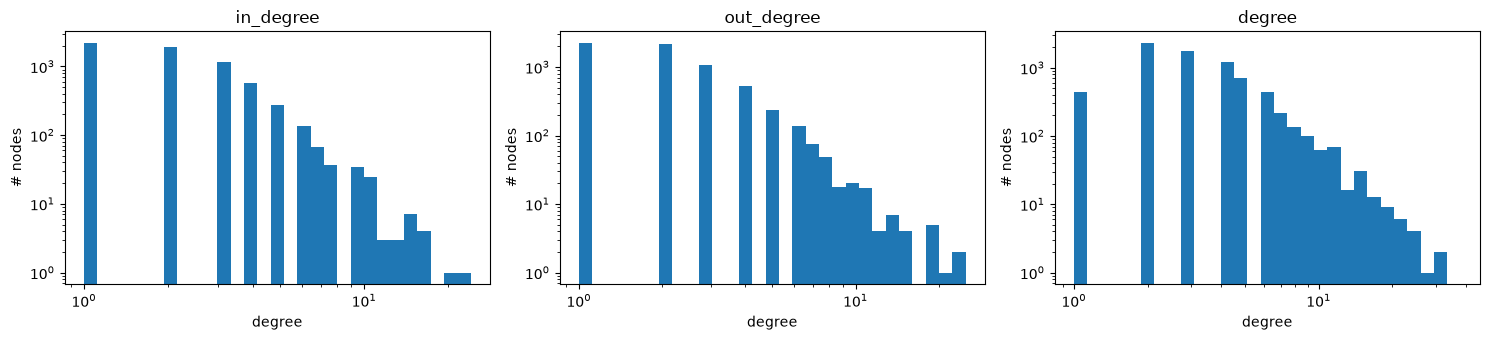

In [15]:
cols = [c for c in ["in_degree", "out_degree", "degree"] if c in metrics]
fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 3.5))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, cols):
    vals = metrics[c][metrics[c] > 0]
    bins = np.logspace(0, np.log10(max(vals.max(), 2)), 30)
    ax.hist(vals, bins=bins)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(c); ax.set_xlabel("degree"); ax.set_ylabel("# nodes")
plt.tight_layout(); plt.show()

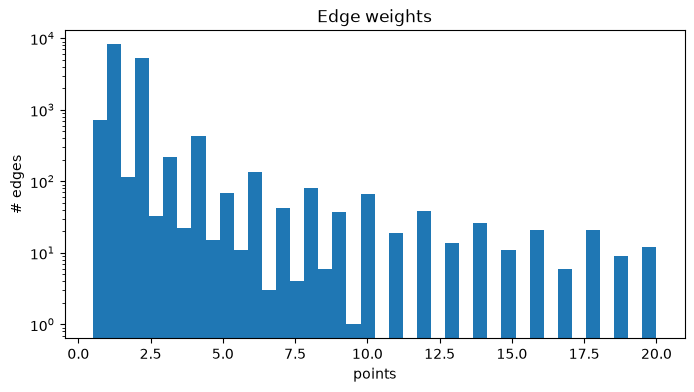

In [16]:
# Edge weight distribution
fig, ax = plt.subplots()
ax.hist(edges_agg["points"], bins=40)
ax.set_yscale("log"); ax.set_xlabel("points"); ax.set_ylabel("# edges"); ax.set_title("Edge weights")
plt.show()

## 5. Centrality

In [17]:
metrics["pagerank"] = pd.Series(nx.pagerank(G, weight="weight"))

# Betweenness is O(n*m); approximate with k sampled sources on larger graphs.
k = None if n <= 1000 else 300
metrics["betweenness"] = pd.Series(nx.betweenness_centrality(UG, k=k, seed=42))

metrics["clustering"] = pd.Series(nx.clustering(UG))
metrics.sort_values("pagerank", ascending=False).head(10)

,in_degree,out_degree,in_points,out_points,degree,strength,pagerank,betweenness,clustering
somar21,7,3,8.0,6.0,9,12.0,0.001844,0.002157,0.027778
Chandan_Kumar_Sinha,23,10,42.5,12.5,27,45.5,0.001522,0.018199,0.014245
sdbhau,4,4,7.0,5.0,7,10.0,0.001516,0.005997,0.000000
Aohane,3,1,7.0,2.0,3,7.0,0.001514,0.000297,0.000000
Dedulia_Sasha,14,16,40.0,34.0,20,52.0,0.001401,0.008224,0.015789
kiketacea,8,11,23.0,34.0,12,34.0,0.001249,0.002662,0.045455
mudshark2,20,1,22.0,1.0,21,23.0,0.001192,0.014244,0.004762
perfectfather,14,14,29.0,43.0,20,43.0,0.001189,0.009930,0.010526
gsingh,4,1,3.5,0.5,4,3.5,0.001176,0.000216,0.000000
capabl4nca,8,4,23.0,13.0,8,21.0,0.001154,0.001269,0.000000


In [18]:
metrics.sort_values("betweenness", ascending=False).head(10)[["degree", "strength", "betweenness", "pagerank"]]

,degree,strength,betweenness,pagerank
Scobiwan,38,48.5,0.025784,0.000961
Johnyfrodo,33,44.5,0.019357,0.000713
Chandan_Kumar_Sinha,27,45.5,0.018199,0.001522
Pogreb-Sergey,30,49.0,0.017347,0.001040
malhamza999,22,24.0,0.015348,0.000263
Khristof,20,31.0,0.015324,0.000950
jonman_t99,19,23.0,0.014824,0.000490
IlliaSav,18,24.0,0.014553,0.000682
mudshark2,21,23.0,0.014244,0.001192
jc241971,17,19.5,0.014059,0.000656


## 6. Assortativity and communities

In [19]:
print("degree assortativity:", round(nx.degree_assortativity_coefficient(G), 4))

# Do similarly rated players connect to each other?
rated = [v for v, d in G.nodes(data=True) if pd.notna(d.get("target_rating"))]
print(f"nodes with target_rating: {len(rated)}")
if len(rated) > 1:
    print("target_rating assortativity:",
          round(nx.numeric_assortativity_coefficient(G.subgraph(rated), "target_rating"), 4))

degree assortativity: 0.1028
nodes with target_rating: 7571
target_rating assortativity: 0.7409


In [20]:
communities = nx.community.louvain_communities(UG, weight="weight", seed=42)
communities = sorted(communities, key=len, reverse=True)
print(f"{len(communities)} communities, modularity = {nx.community.modularity(UG, communities, weight='weight'):.3f}")

comm_map = {v: i for i, c in enumerate(communities) for v in c}
metrics["community"] = pd.Series(comm_map)

attrs = nodes.drop_duplicates("username").set_index("username")
joined = metrics.join(attrs)
top = joined[joined["community"] < 10]
top.groupby("community").agg(
    size=("degree", "size"),
    mean_rating=("target_rating", "mean"),
    mean_acpl=("acpl", "mean"),
    mean_win_rate=("win_rate", "mean"),
    mean_degree=("degree", "mean"),
)

121 communities, modularity = 0.773


,size,mean_rating,mean_acpl,mean_win_rate,mean_degree
community,,,,,
0,697,1602.192253,64.412568,0.483438,4.472023
1,674,1690.934718,57.557116,0.488093,4.686944
2,511,1555.953033,58.845544,0.488430,4.710372
3,386,1755.005181,60.023400,0.488117,4.062176
4,313,1482.581470,65.669660,0.488836,3.530351
5,307,1319.459283,71.834346,0.480109,3.524430
6,290,1812.075862,56.936113,0.496227,3.700000
7,254,2037.429134,48.108857,0.514571,3.181102
8,251,1703.011952,62.609779,0.486119,3.832669


## 7. Do node stats relate to network position?

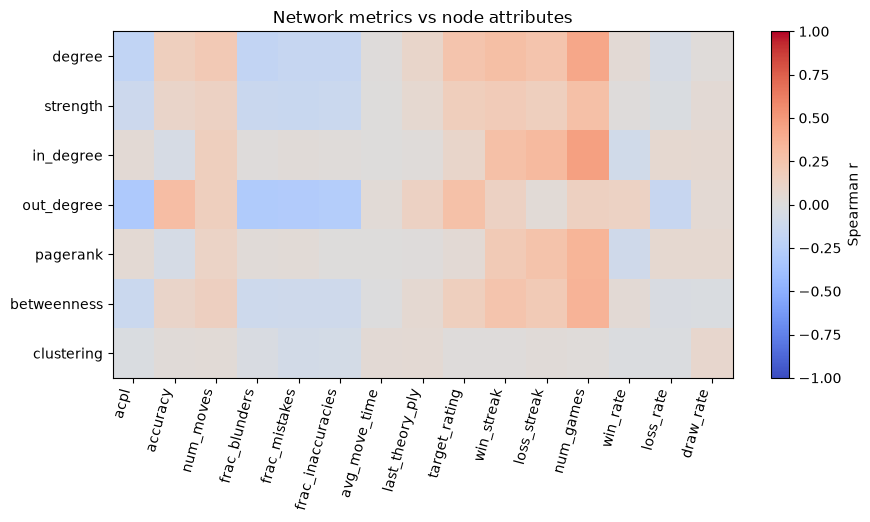

In [21]:
net_cols = [c for c in ["degree", "strength", "in_degree", "out_degree", "pagerank", "betweenness", "clustering"] if c in joined]
attr_cols = attrs.select_dtypes("number").columns.tolist()

corr = joined[net_cols + attr_cols].corr(method="spearman").loc[net_cols, attr_cols]

fig, ax = plt.subplots(figsize=(1 + 0.6 * len(attr_cols), 1 + 0.5 * len(net_cols)))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(attr_cols)), attr_cols, rotation=75, ha="right")
ax.set_yticks(range(len(net_cols)), net_cols)
fig.colorbar(im, label="Spearman r")
ax.set_title("Network metrics vs node attributes")
plt.show()

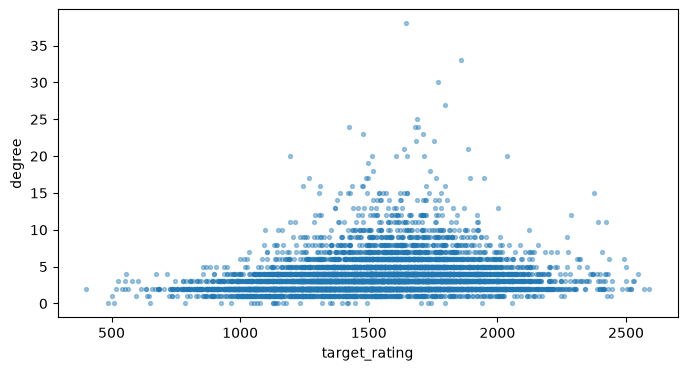

In [25]:
# Example scatter: rating vs. connectivity
fig, ax = plt.subplots()
ax.scatter(joined["target_rating"], joined["degree"], s=8, alpha=0.4)
ax.set_xlabel("target_rating")
ax.set_ylabel("degree"); 
plt.show()

## 8. Visualization

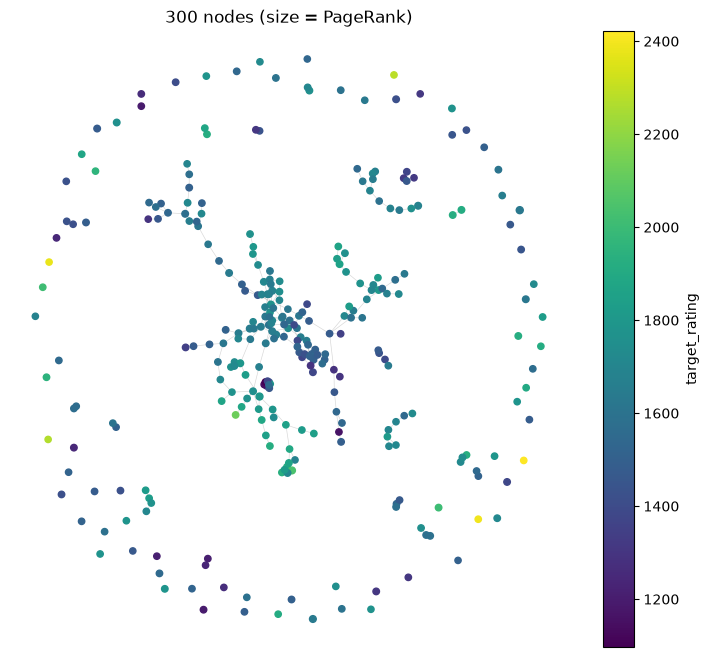

In [26]:
# Draw the largest component; if it's big, keep only the highest-degree nodes.
MAX_DRAW = 300
sub = UG.subgraph(lcc_nodes)
if sub.number_of_nodes() > MAX_DRAW:
    keep = metrics.loc[list(lcc_nodes), "degree"].nlargest(MAX_DRAW).index
    sub = UG.subgraph(keep)

pos = nx.spring_layout(sub, weight="weight", seed=42)
color = [G.nodes[v].get("target_rating", np.nan) for v in sub]
size = 20 + 3000 * metrics.loc[list(sub), "pagerank"].values

fig, ax = plt.subplots(figsize=(9, 8))
nx.draw_networkx_edges(sub, pos, alpha=0.15, width=0.5, ax=ax)
sc = ax.scatter(*zip(*[pos[v] for v in sub]), c=color, s=size, cmap="viridis")
fig.colorbar(sc, label="target_rating")
ax.set_title(f"{sub.number_of_nodes()} nodes (size = PageRank)")
ax.axis("off")
plt.show()